First 5 rows:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Unnamed: 5  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              200 non-null    int64  
 1   Genre                   200 non-null    object 
 2   Age                     200 non-null    int64  
 3   Annual Income (k$)      200 non-null    int64  
 

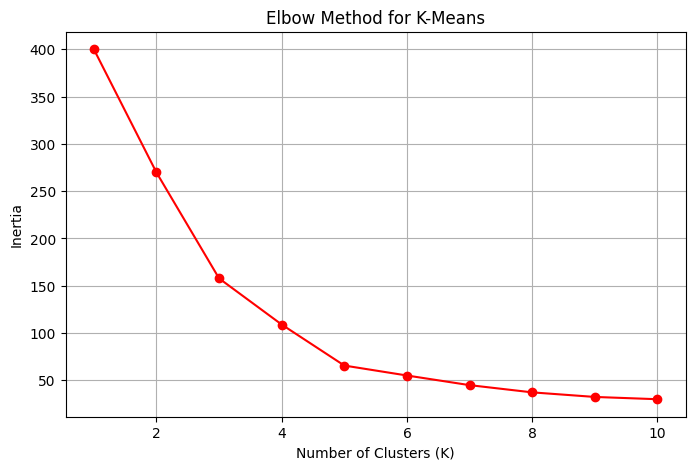


K-MEANS CLUSTERING
Silhouette Score: 0.5547

Number of customers in each cluster:
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


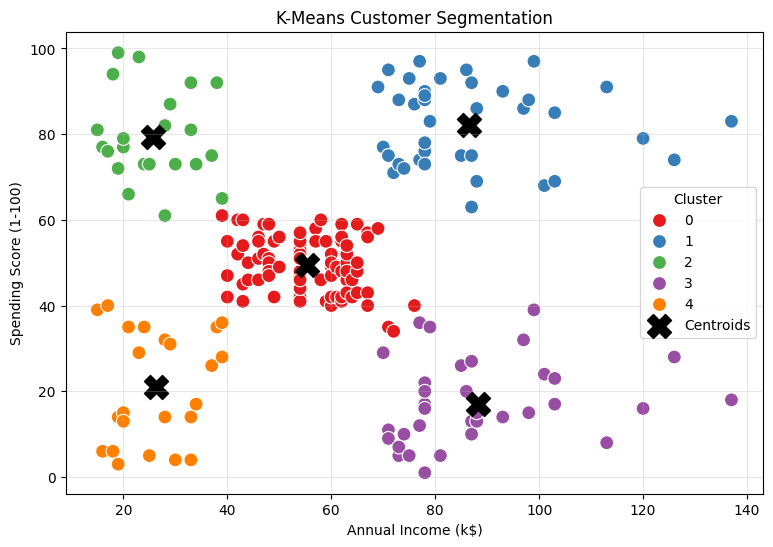

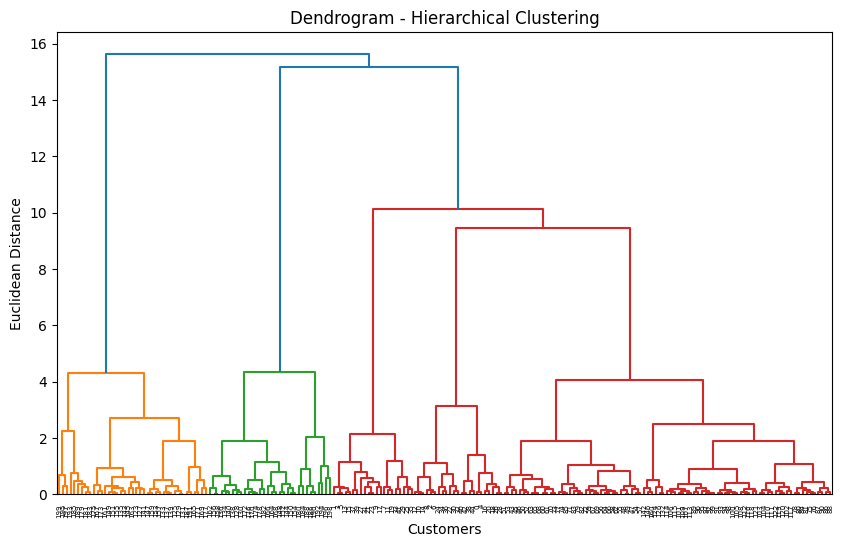


HIERARCHICAL CLUSTERING
Silhouette Score: 0.5538

Number of customers in each cluster:
Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


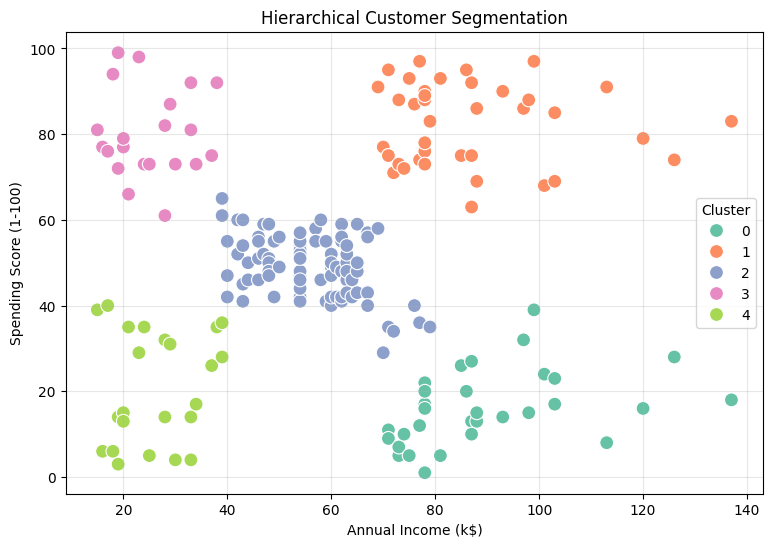


MODEL COMPARISON
              Algorithm  Silhouette Score
                K-Means            0.5547
Hierarchical Clustering            0.5538

K-MEANS CUSTOMER GROUP ANALYSIS
                Annual Income (k$)  Spending Score (1-100)
KMeans_Cluster                                            
0                            55.30                   49.52
1                            86.54                   82.13
2                            25.73                   79.36
3                            88.20                   17.11
4                            26.30                   20.91

Final Dataset:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   

In [2]:
# ASSIGNMENT NO. 7
# IMPLEMENT ANY TWO CLUSTERING ALGORITHMS
# Dataset: Mall_Customers.csv
# Algorithms: K-Means and Hierarchical Clustering

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage


# 1. IMPORT DATASET


df = pd.read_csv("Mall_Customers.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# 2. DATA PRE-PROCESSING



data = df.drop("CustomerID", axis=1)


le = LabelEncoder()
data["Genre"] = le.fit_transform(data["Genre"])

print("\nAfter Label Encoding:")
print(data.head())

# We will use Annual Income and Spending Score
# because the objective is to identify profitable customer groups
X = data[["Annual Income (k$)", "Spending Score (1-100)"]].values

# Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 3. K-MEANS CLUSTERING


# Find optimal K using Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o", color="red")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid()
plt.show()

# Choose K = 5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataframe
df["KMeans_Cluster"] = kmeans_labels

# K-Means Silhouette Score
kmeans_score = silhouette_score(X_scaled, kmeans_labels)

print("\n" + "="*50)
print("K-MEANS CLUSTERING")
print("="*50)
print("Silhouette Score:", round(kmeans_score, 4))

print("\nNumber of customers in each cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())


# 4. K-MEANS VISUALIZATION


plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=kmeans_labels,
    palette="Set1",
    s=100
)

# Convert cluster centers back to original scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=300,
    c="black",
    marker="X",
    label="Centroids"
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()


# 5. HIERARCHICAL CLUSTERING


# Create dendrogram
plt.figure(figsize=(10, 6))

linkage_matrix = linkage(X_scaled, method="ward")

dendrogram(linkage_matrix)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

# Create Agglomerative Clustering model
hc = AgglomerativeClustering(
    n_clusters=5,
    metric="euclidean",
    linkage="ward"
)

hierarchical_labels = hc.fit_predict(X_scaled)

# Add labels to dataframe
df["Hierarchical_Cluster"] = hierarchical_labels

# Hierarchical Silhouette Score
hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("\n" + "="*50)
print("HIERARCHICAL CLUSTERING")
print("="*50)

print("Silhouette Score:", round(hierarchical_score, 4))

print("\nNumber of customers in each cluster:")
print(
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)


# 6. HIERARCHICAL CLUSTER VISUALIZATION


plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=hierarchical_labels,
    palette="Set2",
    s=100
)

plt.title("Hierarchical Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()


# 7. MODEL COMPARISON


comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical Clustering"
    ],
    "Silhouette Score": [
        kmeans_score,
        hierarchical_score
    ]
})

print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)

print(comparison.round(4).to_string(index=False))


# 8. CUSTOMER GROUP ANALYSIS


print("\n" + "="*50)
print("K-MEANS CUSTOMER GROUP ANALYSIS")
print("="*50)

print(
    df.groupby("KMeans_Cluster")[
        ["Annual Income (k$)", "Spending Score (1-100)"]
    ].mean().round(2)
)


# 9. DISPLAY FINAL DATA


print("\nFinal Dataset:")
print(df.head(10))
